<a href="https://colab.research.google.com/github/jhonathanrodriguez1/Curso---FDG2026/blob/main/LABORATORIO_DIRIGIDO_N_%C2%B0_06.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LABORATORIO DIRIGIDO N.° 06 — AutoFlota Andina
**Fundamentos de Gestión de Datos | Semana 6 | 2026-II**

Limpieza de Auto MPG, SQLite, regresión lineal simple y múltiple, métricas, resúmenes estadísticos y diagnósticos. Ejecute todas las celdas en orden.

**Estudiante:** Rodriguez Gonzales Jhonathan Steven · **Sección:** B.

## A. Diagnóstico y limpieza

### Celda 1 — Preparación del entorno y carga de datos

In [ ]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"
columnas = ["rendimiento_mpg", "cilindros", "cilindrada", "potencia", "peso",
            "aceleracion", "anio_modelo", "codigo_origen", "nombre_auto"]
crudo = pd.read_csv(url, sep=r"\s+", names=columnas, na_values="?")
conexion = sqlite3.connect(":memory:")
crudo.to_sql("autos_original", conexion, index=False)
autos = pd.read_sql_query("SELECT * FROM autos_original;", conexion)
autos["marca"] = autos["nombre_auto"].str.split().str[0]
print("Filas y columnas:", autos.shape)

Filas y columnas: (398, 10)


### Celda 2 — Valores faltantes, duplicados y tipos

In [ ]:
faltantes = autos.isna().sum()
print("Valores faltantes por columna (solo las que tienen):")
display(faltantes[faltantes > 0])
print("Filas duplicadas:", autos.duplicated().sum())
display(autos.dtypes)

Valores faltantes por columna (solo las que tienen):


,0
potencia,6


Filas duplicadas: 0


,0
rendimiento_mpg,float64
cilindros,int64
cilindrada,float64
potencia,float64
peso,float64
aceleracion,float64
anio_modelo,int64
codigo_origen,int64
nombre_auto,object
marca,object


**Pregunta 1.** ¿Qué problemas de calidad aparecen en la celda 2: faltantes, duplicados y tipos de dato?

**Respuesta:** El único campo con datos faltantes es potencia, con 6 vehículos sin valor (en el archivo original venían como "?"). No hay filas duplicadas. Los tipos se leyeron bien: rendimiento, cilindrada, potencia, peso y aceleración son float64; cilindros, anio_modelo y codigo_origen son int64; nombre_auto y marca son texto (object). El detalle a cuidar es codigo_origen: aunque es numérico, en realidad es una categoría (1, 2 y 3 son regiones), por lo que no tiene sentido sumarlo ni promediarlo.

### Celda 3 — Inconsistencias en marcas

In [ ]:
variantes = ["vw", "vokswagen", "volkswagen", "chevy", "chevroelt", "chevrolet",
             "maxda", "mazda", "toyouta", "toyota", "mercedes", "mercedes-benz"]
display(autos[autos["marca"].isin(variantes)]["marca"].value_counts().sort_index())
print("Marcas distintas antes de corregir:", autos["marca"].nunique())

,count
marca,
chevroelt,1
chevrolet,43
chevy,3
maxda,2
mazda,10
mercedes,1
mercedes-benz,2
toyota,25
toyouta,1


Marcas distintas antes de corregir: 37


**Pregunta 2.** ¿Qué inconsistencia muestra la celda 3 en la columna marca y por qué afectaría a un groupby?

**Respuesta:** Una misma marca aparece escrita de varias formas, por abreviaturas o errores de digitación: vw, vokswagen y volkswagen; chevy, chevroelt y chevrolet; maxda y mazda; toyouta y toyota; mercedes y mercedes-benz. Por eso el conteo inicial da 37 marcas distintas. Un groupby trata cada texto como un grupo diferente, así que Volkswagen quedaría partida en tres grupos: sus conteos se verían menores y los promedios por marca se calcularían sobre grupos incompletos.

### Celda 4 — Imputación de potencia

In [ ]:
mediana = autos["potencia"].median()
promedio = autos["potencia"].mean()
print("Mediana de potencia:", mediana, "| promedio:", round(promedio, 2))
autos["potencia"] = autos["potencia"].fillna(mediana)
print("Faltantes en potencia después de imputar:", autos["potencia"].isna().sum())

Mediana de potencia: 93.5 | promedio: 104.47
Faltantes en potencia después de imputar: 0


**Pregunta 3.** ¿Por qué se imputa potencia con la mediana y no con el promedio? ¿Qué otra opción existía?

**Respuesta:** La potencia tiene autos de muy alta potencia (hasta 230 hp) que jalan el promedio hacia arriba: el promedio es 104.47 mientras que la mediana es 93.5. La mediana no se ve afectada por esos extremos, así que representa mejor a un auto típico y evita asignar a los 6 faltantes una potencia exagerada. La alternativa era eliminar esas 6 filas con dropna(), perdiendo 1.5 % de los datos (se compara en el Reto 3). Otra opción más fina sería imputar con la mediana según el número de cilindros.

### Celda 5 — Origen, año y marcas

In [ ]:
autos["origen"] = autos["codigo_origen"].map({1: "USA", 2: "Europa", 3: "Japón"})
autos["anio"] = 1900 + autos["anio_modelo"]
correcciones = {"vw": "volkswagen", "vokswagen": "volkswagen", "chevy": "chevrolet",
                "chevroelt": "chevrolet", "maxda": "mazda", "toyouta": "toyota",
                "mercedes": "mercedes-benz"}
autos["marca"] = autos["marca"].replace(correcciones)
print("Marcas distintas después de corregir:", autos["marca"].nunique())
display(autos[["nombre_auto", "marca", "origen", "anio"]].head())

Marcas distintas después de corregir: 30


,nombre_auto,marca,origen,anio
0,chevrolet chevelle malibu,chevrolet,USA,1970
1,buick skylark 320,buick,USA,1970
2,plymouth satellite,plymouth,USA,1970
3,amc rebel sst,amc,USA,1970
4,ford torino,ford,USA,1970


**Pregunta 4.** ¿Qué corrigen origen, anio y replace()? ¿Cuántas marcas distintas quedan?

**Respuesta:** Con map() el código de origen pasa a una etiqueta legible (1 = USA, 2 = Europa, 3 = Japón). La columna anio convierte el año de dos cifras en uno completo sumando 1900 (70 pasa a 1970). replace() aplica un diccionario que lleva cada variante mal escrita a su nombre correcto. Después de la corrección quedan 30 marcas distintas, 7 menos que las 37 iniciales.

### Celda 6 — Valores atípicos con IQR

In [ ]:
q1 = autos["potencia"].quantile(0.25)
q3 = autos["potencia"].quantile(0.75)
iqr = q3 - q1
limite_inf = q1 - 1.5 * iqr
limite_sup = q3 + 1.5 * iqr
print("Q1:", q1, "| Q3:", q3, "| IQR:", iqr)
print("Límites:", round(limite_inf, 1), "y", round(limite_sup, 1))
atipicos = autos[(autos["potencia"] < limite_inf) | (autos["potencia"] > limite_sup)]
print("Autos atípicos en potencia:", len(atipicos))
display(atipicos[["nombre_auto", "potencia", "cilindros", "peso"]]
        .sort_values("potencia", ascending=False).head(5))

Q1: 76.0 | Q3: 125.0 | IQR: 49.0
Límites: 2.5 y 198.5
Autos atípicos en potencia: 11


,nombre_auto,potencia,cilindros,peso
116,pontiac grand prix,230.0,8,4278.0
13,buick estate wagon (sw),225.0,8,3086.0
8,pontiac catalina,225.0,8,4425.0
95,buick electra 225 custom,225.0,8,4951.0
6,chevrolet impala,220.0,8,4354.0


**Pregunta 5.** ¿Cuáles son los límites del IQR en potencia y cuántos autos los superan? ¿Por qué se conservan?

**Respuesta:** Con Q1 = 76 y Q3 = 125, el IQR es 49 y los límites quedan en 2.5 y 198.5 hp. Ningún auto está por debajo; 11 superan el límite superior, el mayor es el Pontiac Grand Prix con 230 hp. Se conservan porque no son errores de registro: son autos grandes con motores de 8 cilindros y mucho peso, coherentes con su potencia. Eliminarlos haría que el modelo no aprenda cómo rinden los vehículos más potentes.

### Celda 7 — Boxplots y marca de atípicos

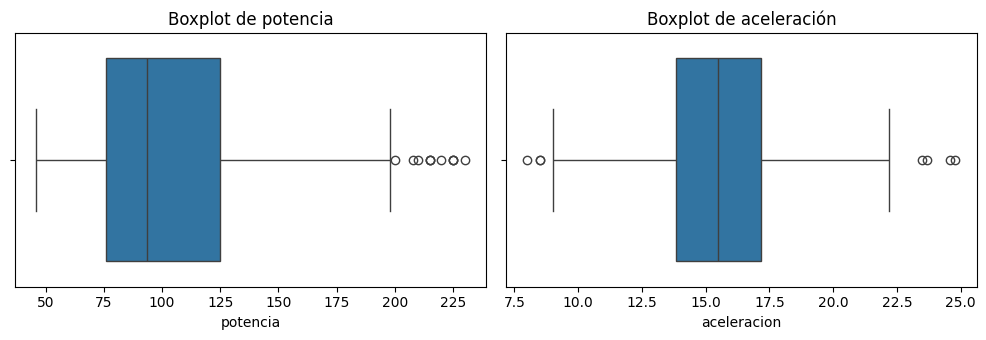

Autos marcados como atípicos (se conservan): 11


In [ ]:
autos["potencia_atipica"] = (autos["potencia"] < limite_inf) | (autos["potencia"] > limite_sup)
fig, ejes = plt.subplots(1, 2, figsize=(10, 3.5))
sns.boxplot(x=autos["potencia"], ax=ejes[0])
ejes[0].set_title("Boxplot de potencia")
sns.boxplot(x=autos["aceleracion"], ax=ejes[1])
ejes[1].set_title("Boxplot de aceleración")
plt.tight_layout()
plt.show()
print("Autos marcados como atípicos (se conservan):", autos["potencia_atipica"].sum())

**Pregunta 6.** ¿Qué muestran los boxplots de potencia y de aceleración?

**Respuesta:** El boxplot de potencia es asimétrico: la caja va de 76 a 125, con la mediana en 93.5 más cerca del borde izquierdo, y los atípicos aparecen solo a la derecha (entre 200 y 230 hp). Esto confirma una cola larga de autos muy potentes. El de aceleración es más equilibrado, con mediana alrededor de 15.5 segundos y unos pocos puntos aislados en ambos extremos (autos muy rápidos cerca de 8 s y muy lentos sobre 23 s). En lugar de borrar los atípicos de potencia, se marcan con la columna potencia_atipica para poder identificarlos.

### Celda 8 — Guardar datos limpios en SQLite

In [ ]:
autos.to_sql("autos_limpio", conexion, index=False, if_exists="replace")
consulta = """SELECT
  (SELECT COUNT(*) FROM autos_original) AS filas_original,
  (SELECT COUNT(*) FROM autos_limpio) AS filas_limpio,
  (SELECT COUNT(*) FROM autos_original WHERE potencia IS NULL) AS faltantes_original,
  (SELECT COUNT(*) FROM autos_limpio WHERE potencia IS NULL) AS faltantes_limpio;"""
display(pd.read_sql_query(consulta, conexion))

,filas_original,filas_limpio,faltantes_original,faltantes_limpio
0,398,398,6,0


**Pregunta 7.** ¿Qué cambió entre autos_original y autos_limpio? ¿Por qué no se sobrescribe la tabla original?

**Respuesta:** Las dos tablas conservan 398 filas, porque no se eliminó ningún auto. La diferencia es que autos_original mantiene los 6 nulos de potencia y autos_limpio tiene 0, además de las columnas nuevas (marca corregida, origen, anio y potencia_atipica). La tabla original no se toca para tener trazabilidad: permite revisar qué se modificó, deshacer una decisión de limpieza si resulta equivocada y probar otros tratamientos sobre los datos crudos, como se hace en el Reto 3.

## B. Regresión lineal

### Celda 9 — Separación entrenamiento y prueba

In [ ]:
y = autos["rendimiento_mpg"]
X_simple = autos[["peso"]]
X_train, X_test, y_train, y_test = train_test_split(
    X_simple, y, test_size=0.2, random_state=42)
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)

Entrenamiento: (318, 1) | Prueba: (80, 1)


**Pregunta 8.** ¿Cuántos autos hay en entrenamiento y en prueba? ¿Para qué sirven la separación y random_state?

**Respuesta:** Quedan 318 autos para entrenamiento (80 %) y 80 para prueba (20 %); el 1 que aparece en el shape es la cantidad de columnas (solo peso). El modelo aprende con los 318 y luego se mide con los 80 que nunca vio, lo que simula cómo funcionaría con autos nuevos y evita confiar en un modelo que solo memorizó sus datos. random_state=42 fija la semilla del reparto aleatorio, de modo que cada vez que se ejecute el notebook salen los mismos grupos y las mismas métricas.

### Celda 10 — Regresión simple con scikit-learn

Coeficiente de peso: -0.00781
Intercepto: 46.78
{'R2': 0.723, 'MAE': 3.12, 'MSE': 14.89, 'RMSE': np.float64(3.86)}
                            OLS Regression Results                            
Dep. Variable:        rendimiento_mpg   R-squared:                       0.684
Model:                            OLS   Adj. R-squared:                  0.683
Method:                 Least Squares   F-statistic:                     685.5
Date:                Mon, 09 Nov 2026   Prob (F-statistic):           3.80e-81
Time:                        04:31:05   Log-Likelihood:                -925.80
No. Observations:                 318   AIC:                             1856.
Df Residuals:                     316   BIC:                             1863.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
----------------

,coeficiente,p_valor,IC_95_inf,IC_95_sup
const,46.782063,3.145697e-154,44.972403,48.591724
peso,-0.007805,3.799579e-81,-0.008392,-0.007219


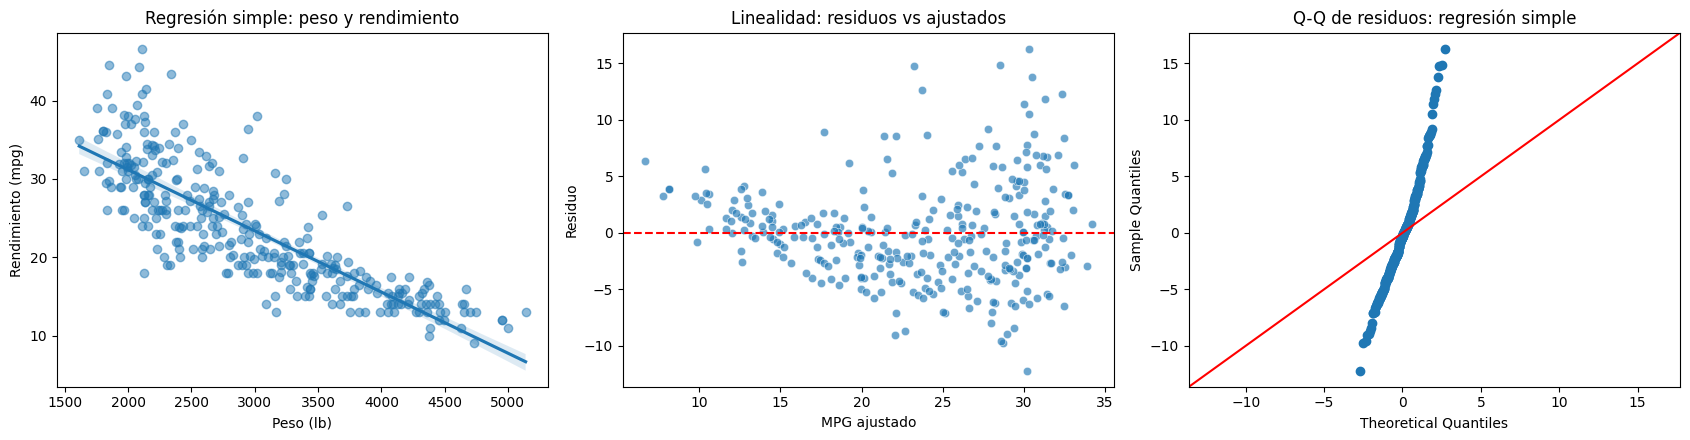

In [ ]:
def metricas(y_real, y_pred):
    mse = mean_squared_error(y_real, y_pred)
    return {"R2": round(r2_score(y_real, y_pred), 3),
            "MAE": round(mean_absolute_error(y_real, y_pred), 2),
            "MSE": round(mse, 2),
            "RMSE": round(np.sqrt(mse), 2)}

modelo_simple = LinearRegression()
modelo_simple.fit(X_train, y_train)
pred_simple = modelo_simple.predict(X_test)
print("Coeficiente de peso:", round(modelo_simple.coef_[0], 5))
print("Intercepto:", round(modelo_simple.intercept_, 2))
res_simple = metricas(y_test, pred_simple)
print(res_simple)

# Resumen estadístico, coeficientes y p-valores (regresión simple)
import statsmodels.api as sm
X_simple_sm = sm.add_constant(X_train)
modelo_simple_sm = sm.OLS(y_train, X_simple_sm).fit()
print(modelo_simple_sm.summary())
print("\nCoeficientes y p-valores (entrenamiento):")
display(pd.DataFrame({"coeficiente": modelo_simple_sm.params,
                      "p_valor": modelo_simple_sm.pvalues,
                      "IC_95_inf": modelo_simple_sm.conf_int()[0],
                      "IC_95_sup": modelo_simple_sm.conf_int()[1]}))

# Gráficas de linealidad, residuos y Q-Q (regresión simple)
ajustados_simple = modelo_simple_sm.fittedvalues
residuos_simple = modelo_simple_sm.resid
fig, ejes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.regplot(x=X_train["peso"], y=y_train, ax=ejes[0], scatter_kws={"alpha": 0.5})
ejes[0].set(title="Regresión simple: peso y rendimiento", xlabel="Peso (lb)", ylabel="Rendimiento (mpg)")
sns.scatterplot(x=ajustados_simple, y=residuos_simple, ax=ejes[1], alpha=0.65)
ejes[1].axhline(0, color="red", linestyle="--")
ejes[1].set(title="Linealidad: residuos vs ajustados", xlabel="MPG ajustado", ylabel="Residuo")
sm.qqplot(residuos_simple, line="45", ax=ejes[2])
ejes[2].set_title("Q-Q de residuos: regresión simple")
plt.tight_layout()
plt.show()

**Pregunta 9.** Interprete el coeficiente de peso, el intercepto y las cuatro métricas del modelo simple.

**Respuesta:** El coeficiente de peso es −0.00781: por cada libra adicional el rendimiento baja en promedio 0.0078 mpg, es decir, unos 0.78 mpg por cada 100 lb. El signo negativo confirma que los autos más pesados recorren menos millas por galón. El intercepto, 46.78 mpg, es el rendimiento que daría la recta para un auto de peso cero; sirve para ubicar la recta, pero no tiene sentido real. En prueba, R² = 0.723 indica que el peso explica alrededor del 72 % de la variación del rendimiento respecto de predecir siempre la media. El MAE = 3.12 dice que, en promedio, la predicción se equivoca por 3.12 mpg; el MSE = 14.89 está en mpg² y castiga más los errores grandes; y el RMSE = 3.86 mpg lleva ese error a las unidades originales. Como el RMSE es mayor que el MAE, hay algunos autos con errores más grandes que el resto.

### Celda 11 — Regresión múltiple con scikit-learn

,variable,coeficiente
0,peso,-0.0070
1,potencia,0.0027
2,cilindrada,0.0026
3,aceleracion,0.0797
4,anio,0.8008


Intercepto: -1539.97
{'R2': 0.826, 'MAE': 2.46, 'MSE': 9.38, 'RMSE': np.float64(3.06)}
                            OLS Regression Results                            
Dep. Variable:        rendimiento_mpg   R-squared:                       0.804
Model:                            OLS   Adj. R-squared:                  0.801
Method:                 Least Squares   F-statistic:                     255.8
Date:                Mon, 09 Nov 2026   Prob (F-statistic):          4.62e-108
Time:                        04:31:06   Log-Likelihood:                -850.20
No. Observations:                 318   AIC:                             1712.
Df Residuals:                     312   BIC:                             1735.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------

,coeficiente,p_valor,IC_95_inf,IC_95_sup
const,-1539.973203,2.340422e-29,-1782.300119,-1297.646287
peso,-0.007029,1.572087e-18,-0.008506,-0.005552
potencia,0.002657,8.646462e-01,-0.027988,0.033302
cilindrada,0.002625,6.714209e-01,-0.009540,0.014790
aceleracion,0.079661,4.831939e-01,-0.143612,0.302933
anio,0.800782,9.879430e-31,0.678449,0.923114


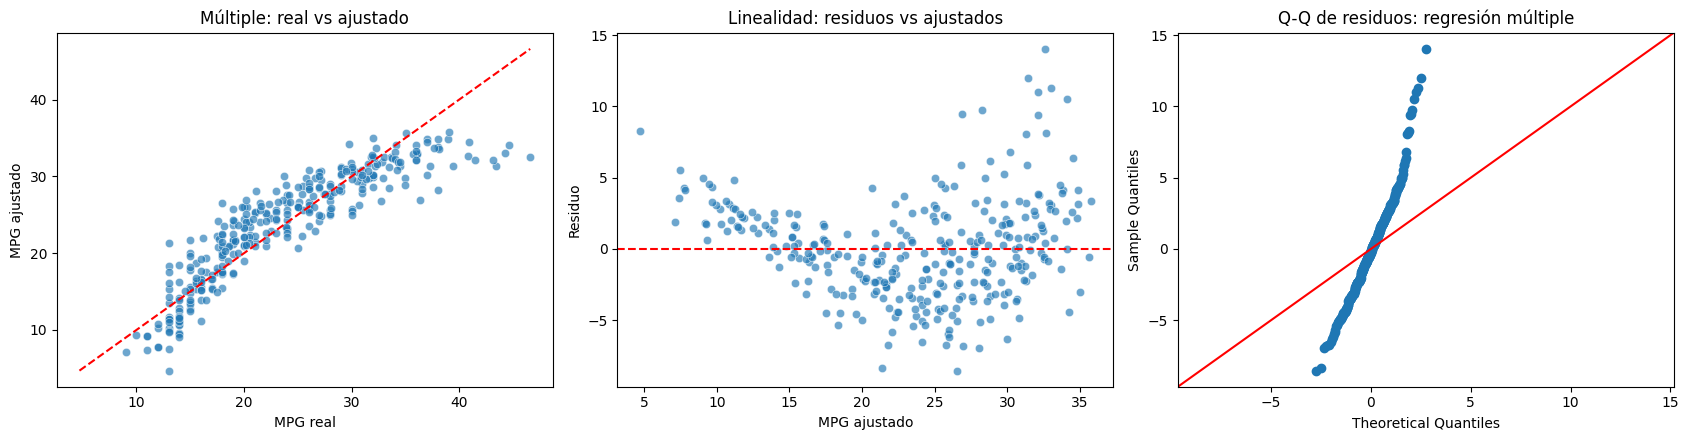

In [ ]:
variables = ["peso", "potencia", "cilindrada", "aceleracion", "anio"]
Xm_train, Xm_test, ym_train, ym_test = train_test_split(
    autos[variables], y, test_size=0.2, random_state=42)
modelo_multiple = LinearRegression()
modelo_multiple.fit(Xm_train, ym_train)
pred_multiple = modelo_multiple.predict(Xm_test)
display(pd.DataFrame({"variable": variables, "coeficiente": modelo_multiple.coef_.round(4)}))
print("Intercepto:", round(modelo_multiple.intercept_, 2))
res_multiple = metricas(ym_test, pred_multiple)
print(res_multiple)

# Resumen estadístico, coeficientes y p-valores (regresión múltiple)
Xm_const = sm.add_constant(Xm_train)
modelo_multiple_sm = sm.OLS(ym_train, Xm_const).fit()
print(modelo_multiple_sm.summary())
print("\nCoeficientes y p-valores (entrenamiento):")
display(pd.DataFrame({"coeficiente": modelo_multiple_sm.params,
                      "p_valor": modelo_multiple_sm.pvalues,
                      "IC_95_inf": modelo_multiple_sm.conf_int()[0],
                      "IC_95_sup": modelo_multiple_sm.conf_int()[1]}))

# Gráficas de linealidad, residuos y Q-Q (regresión múltiple)
ajustados_multiple = modelo_multiple_sm.fittedvalues
residuos_multiple = modelo_multiple_sm.resid
fig, ejes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.scatterplot(x=ym_train, y=ajustados_multiple, ax=ejes[0], alpha=0.65)
limites = [min(ym_train.min(), ajustados_multiple.min()), max(ym_train.max(), ajustados_multiple.max())]
ejes[0].plot(limites, limites, "r--")
ejes[0].set(title="Múltiple: real vs ajustado", xlabel="MPG real", ylabel="MPG ajustado")
sns.scatterplot(x=ajustados_multiple, y=residuos_multiple, ax=ejes[1], alpha=0.65)
ejes[1].axhline(0, color="red", linestyle="--")
ejes[1].set(title="Linealidad: residuos vs ajustados", xlabel="MPG ajustado", ylabel="Residuo")
sm.qqplot(residuos_multiple, line="45", ax=ejes[2])
ejes[2].set_title("Q-Q de residuos: regresión múltiple")
plt.tight_layout()
plt.show()

**Pregunta 10.** Interprete los coeficientes del modelo múltiple. ¿Qué llama la atención en potencia y por qué?

**Respuesta:** Cada coeficiente se lee manteniendo fijas las otras cuatro variables. Peso (−0.0070): cada libra extra resta unos 0.007 mpg, casi lo mismo que en el modelo simple, y es la variable más confiable (p ≈ 1.6e-18). Año (+0.8008): cada año más reciente suma cerca de 0.8 mpg, reflejo de la mejora tecnológica entre 1970 y 1982. Aceleración (+0.0797) y cilindrada (+0.0026) tienen efectos pequeños. El intercepto (−1539.97) no se interpreta, porque corresponde al año 0. Lo llamativo es potencia: su coeficiente sale positivo (+0.0027), como si más caballos mejoraran el rendimiento, y su p-valor (0.865) muestra que no es significativo. La causa es la multicolinealidad: potencia está muy correlacionada con peso y cilindrada, que ya explican casi la misma información, y el modelo no puede separar el efecto propio de cada una. Por eso ese coeficiente no debe interpretarse por sí solo.

### Celda 12 — Comparación de modelos y gráfica de prueba

,simple (peso),múltiple (5 variables)
R2,0.723,0.826
MAE,3.120,2.460
MSE,14.890,9.380
RMSE,3.860,3.060


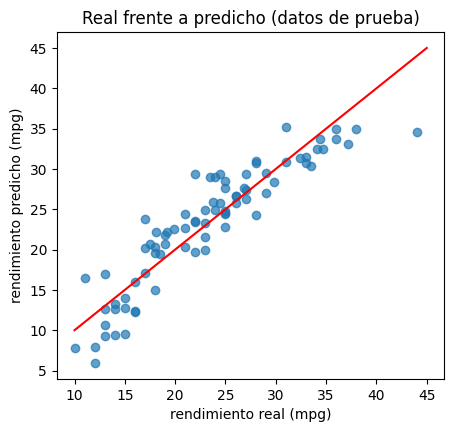

In [ ]:
comparacion = pd.DataFrame({"simple (peso)": res_simple,
                           "múltiple (5 variables)": res_multiple})
display(comparacion)
plt.figure(figsize=(5, 4.5))
plt.scatter(ym_test, pred_multiple, alpha=0.7)
plt.plot([10, 45], [10, 45], color="red")
plt.xlabel("rendimiento real (mpg)")
plt.ylabel("rendimiento predicho (mpg)")
plt.title("Real frente a predicho (datos de prueba)")
plt.show()

**Pregunta 11.** Compare las métricas de los dos modelos. ¿Cuál es mejor y por qué se compara con los datos de prueba?

**Respuesta:** El modelo múltiple gana en las cuatro métricas: R² sube de 0.723 a 0.826 y los errores bajan (MAE de 3.12 a 2.46 mpg, MSE de 14.89 a 9.38 y RMSE de 3.86 a 3.06 mpg). En la práctica, agregar potencia, cilindrada, aceleración y año reduce el error típico en casi 0.8 mpg, y en el gráfico los puntos quedan cerca de la diagonal roja. La comparación se hace con los 80 autos de prueba porque son datos que ningún modelo usó para ajustarse; las métricas de entrenamiento suelen salir optimistas y no muestran si el modelo sirve para autos nuevos.

## Actividad 3 — Predicción para la flota

### Celda 13 — Candidatos de compra

In [ ]:
candidatos = pd.DataFrame({
    "candidato": ["A", "B", "C"],
    "peso": [2200, 3000, 4200],
    "potencia": [80, 110, 160],
    "cilindrada": [100, 200, 350],
    "aceleracion": [16, 15, 12],
    "anio": [1982, 1980, 1978]})
candidatos["rendimiento_predicho"] = modelo_multiple.predict(candidatos[variables]).round(1)
display(candidatos)

,candidato,peso,potencia,cilindrada,aceleracion,anio,rendimiento_predicho
0,A,2200,80,100,16,1982,33.5
1,B,3000,110,200,15,1980,26.5
2,C,4200,160,350,12,1978,16.7


**A.** ¿Qué candidato rinde más y cuál menos? ¿Qué características lo explican?

**Respuesta:** El candidato A tiene el mejor rendimiento estimado (33.5 mpg), el B queda en medio (26.5 mpg) y el C es el que menos rinde (16.7 mpg). A combina las dos características que más pesan en el modelo a favor del rendimiento: es el más liviano (2200 lb) y el más reciente (1982); además tiene motor pequeño (80 hp, 100 de cilindrada). C es lo contrario: pesa casi el doble (4200 lb), es el más antiguo (1978) y tiene el motor más grande (160 hp, 350 de cilindrada). Solo la diferencia de 2000 lb ya representa unos 14 mpg menos según el coeficiente de peso.

**B.** Redacte una recomendación para AutoFlota Andina e indique los límites del modelo.

**Respuesta:** Recomendación: priorizar vehículos con el perfil del candidato A, livianos y de motor pequeño, porque recorrerían el doble de millas por galón que el C (33.5 frente a 16.7 mpg), lo que reduce el gasto en combustible de la flota. El B puede considerarse si se necesita más capacidad de carga o potencia. Límites: el modelo se entrenó con autos de 1970 a 1982, por lo que sus predicciones son solo ilustrativas y no aplican a vehículos actuales; tiene un error típico de unos 3 mpg (RMSE = 3.06); el coeficiente de potencia no es confiable por la multicolinealidad; y no considera precio, mantenimiento, tipo de ruta ni condiciones de manejo, que también deben entrar en la decisión de compra.

## Retos de aplicación

### Celda 14 — Reto 1: variables por separado

In [ ]:
resultados = []
for variable in ["peso", "potencia", "cilindrada", "aceleracion", "anio"]:
    Xv_train, Xv_test, yv_train, yv_test = train_test_split(
        autos[[variable]], y, test_size=0.2, random_state=42)
    modelo = LinearRegression().fit(Xv_train, yv_train)
    resultados.append({"variable": variable,
                       "coeficiente": round(modelo.coef_[0], 4),
                       **metricas(yv_test, modelo.predict(Xv_test))})
tabla_simples = pd.DataFrame(resultados).sort_values("R2", ascending=False)
display(tabla_simples)

,variable,coeficiente,R2,MAE,MSE,RMSE
0,peso,-0.0078,0.723,3.12,14.89,3.86
2,cilindrada,-0.0617,0.663,3.39,18.10,4.25
1,potencia,-0.1640,0.640,3.51,19.37,4.40
4,anio,1.2914,0.287,5.36,38.32,6.19
3,aceleracion,1.1196,0.284,4.99,38.51,6.21


**Pregunta de cierre.** ¿Qué variable explica mejor el rendimiento por sí sola y cuál peor? Sustente con R² y RMSE e interprete el signo de los coeficientes.

**Respuesta:** El peso es la mejor variable individual: tiene el R² más alto (0.723) y el menor error (RMSE = 3.86 mpg). La peor es la aceleración, con R² = 0.284 y RMSE = 6.21 mpg, casi empatada con el año (R² = 0.287); ninguna de las dos alcanza a explicar ni un tercio de la variación por sí sola. Los signos son lógicos: peso (−0.0078), cilindrada (−0.0617) y potencia (−0.1640) son negativos, porque autos más grandes y potentes consumen más. Año (+1.2914) es positivo por la mejora tecnológica en el periodo. Aceleración (+1.1196) también es positiva porque mide los segundos para acelerar: un valor alto corresponde a un auto más lento y de motor más pequeño, que gasta menos. Son asociaciones, no necesariamente causas.

### Celda 15 — Reto 2: combinaciones de variables

In [ ]:
dummies = pd.get_dummies(autos["origen"], prefix="origen", drop_first=True).astype(int)
X_todo = pd.concat([autos[variables], dummies], axis=1)
combinaciones = {
    "peso + anio": ["peso", "anio"],
    "peso + potencia + anio": ["peso", "potencia", "anio"],
    "5 variables": variables,
    "5 variables + origen": list(X_todo.columns),
}
filas = []
for nombre, columnas_x in combinaciones.items():
    Xc_train, Xc_test, yc_train, yc_test = train_test_split(
        X_todo[columnas_x], y, test_size=0.2, random_state=42)
    modelo = LinearRegression().fit(Xc_train, yc_train)
    r = metricas(yc_test, modelo.predict(Xc_test))
    n, p = len(yc_test), len(columnas_x)
    r["R2_ajustado"] = round(1 - (1 - r["R2"]) * (n - 1) / (n - p - 1), 3)
    filas.append({"modelo": nombre, "variables": p, **r})
modelo_origen = modelo
print(dict(zip(X_todo.columns, modelo_origen.coef_.round(3))))
tabla_combos = pd.DataFrame(filas)
display(tabla_combos)

{'peso': np.float64(-0.007), 'potencia': np.float64(-0.014), 'cilindrada': np.float64(0.017), 'aceleracion': np.float64(0.07), 'anio': np.float64(0.827), 'origen_Japón': np.float64(-0.294), 'origen_USA': np.float64(-2.925)}


,modelo,variables,R2,MAE,MSE,RMSE,R2_ajustado
0,peso + anio,2,0.824,2.45,9.44,3.07,0.819
1,peso + potencia + anio,3,0.824,2.45,9.44,3.07,0.817
2,5 variables,5,0.826,2.46,9.38,3.06,0.814
3,5 variables + origen,7,0.843,2.29,8.47,2.91,0.828


**Pregunta de cierre.** ¿Qué combinación tiene el mayor R² ajustado? ¿Cuánto aporta agregar el origen y cuál es su categoría de referencia?

**Respuesta:** El mayor R² ajustado es el de 5 variables + origen (0.828), por encima de peso + año (0.819), peso + potencia + año (0.817) y las 5 variables solas (0.814). Un dato interesante es que peso + año, con solo 2 variables, supera a las 5 variables cuando se penaliza por cantidad de predictores: potencia, cilindrada y aceleración casi no añaden información. Agregar el origen sube el R² de prueba de 0.826 a 0.843 y baja el RMSE de 3.06 a 2.91 mpg. La categoría de referencia es Europa: drop_first=True elimina la primera en orden alfabético (Europa, Japón, USA), por eso solo quedan origen_Japón y origen_USA. Con las demás variables fijas, un auto de USA rinde unos 2.9 mpg menos que uno europeo (−2.925) y uno japonés prácticamente igual (−0.294).

### Celda 16 — Reto 3: imputar o eliminar

In [ ]:
original = pd.read_sql_query(
    "SELECT * FROM autos_original WHERE potencia IS NOT NULL;", conexion)
original["anio"] = 1900 + original["anio_modelo"]
Xe_train, Xe_test, ye_train, ye_test = train_test_split(
    original[variables], original["rendimiento_mpg"], test_size=0.2, random_state=42)
modelo_sin = LinearRegression().fit(Xe_train, ye_train)
print("Filas usadas:", len(original), "frente a", len(autos))
print("Eliminando faltantes:", metricas(ye_test, modelo_sin.predict(Xe_test)))
print("Imputando mediana: ", res_multiple)

Filas usadas: 392 frente a 398
Eliminando faltantes: {'R2': 0.793, 'MAE': 2.51, 'MSE': 10.58, 'RMSE': np.float64(3.25)}
Imputando mediana:  {'R2': 0.826, 'MAE': 2.46, 'MSE': 9.38, 'RMSE': np.float64(3.06)}


**Pregunta de cierre.** ¿Cuántos autos usa cada opción y cómo cambian las métricas? ¿Por qué la comparación debe hacerse con cuidado?

**Respuesta:** Eliminando los faltantes se trabaja con 392 autos y se obtiene R² = 0.793 y RMSE = 3.25 mpg; imputando con la mediana se usan los 398 y se logra R² = 0.826 y RMSE = 3.06 mpg. A primera vista la imputación parece mejor, pero la comparación no es justa: al cambiar el número de filas, train_test_split reparte otros autos en entrenamiento y prueba, así que cada modelo se evalúa con un grupo de prueba distinto y la diferencia puede deberse a qué autos tocaron en cada partición. Además, los 6 valores imputados no son mediciones reales sino estimaciones. Para una comparación rigurosa habría que evaluar ambos sobre el mismo conjunto de prueba o usar validación cruzada.

### Conclusiones

1. **Calidad de datos.** El conjunto Auto MPG tenía 6 potencias faltantes, ningún duplicado y 37 nombres de marca que en realidad eran 30. Se imputó con la mediana (93.5), se unificaron las marcas y se conservaron los 11 atípicos de potencia por ser autos reales, guardando el resultado en autos_limpio sin alterar autos_original.
2. **Modelos.** El peso solo ya explica el 72 % de la variación del rendimiento (R² = 0.723), pero el modelo múltiple predice mejor (R² = 0.826, RMSE = 3.06 mpg) y agregar el origen lo mejora a R² = 0.843. Más variables no siempre ayudan: potencia pierde significancia por su multicolinealidad con peso y cilindrada.
3. **Negocio.** Para AutoFlota Andina conviene priorizar vehículos livianos y recientes como el candidato A (33.5 mpg frente a 16.7 del C). Como el modelo se basa en autos de 1970 a 1982 y tiene un error de unos ±3 mpg, sus predicciones deben usarse solo como referencia, junto con costos, mantenimiento y uso real.